In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
import pandas as pd
from datetime import datetime
import pydicom
import matplotlib.image as mpimg
import csv
import re
import nibabel as nib
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from sklearn.impute import KNNImputer
from sklearn.model_selection import StratifiedKFold


from utils.dcm2niix import list_nifti_files_no_ex

# Source of RAW DICOMs
BERN_PATH='/nasdata/Berner_Daten/Other_Side_Bilddaten' 
# Project data path
DATA_PATH='/home/bule/berner_daten_analyse/data'

PROCESSED_PATH=os.path.join(DATA_PATH, 'nifti','processed')

# IMAGES ------------------------------------------------------------------------------------

In [2]:
columns = ["Patient_ID", "dwi_defaced_raw", "anatomic_defaced_raw", "dwi_skull_normalized", "anatomic_skull_normalized",
           "anatomic_defacing_mask", "anatomic_bet_mask", "dwi_defaced_normalized", "anatomic_defaced_normalized",
           "dwi_skull_raw", "anatomic_skull_raw", "dwi_bet_raw", "anatomic_bet_raw",
           "dwi_bet_normalized", "anatomic_bet_normalized"]

only_2_df=pd.read_csv(os.path.join(DATA_PATH, 'only2_third_try_df.csv'))
dwi_df=only_2_df[only_2_df['Modality']=='dwi'][['Patient_ID','Date']]

patient_dict = {}
for file_path in list_nifti_files_no_ex(PROCESSED_PATH):
    parts = file_path.split("/")
    try:
        patient_id = parts[7]  # Extract patient ID from the path
    except IndexError:
        continue
    # If patient ID is not in ict, initialize entry
    if patient_id not in patient_dict:
        patient_dict[patient_id] = {"Patient_ID": patient_id}
    # Determine corresponding column
    for col in columns[1:]:  # Skip "Patient_ID
        if col in file_path:
            patient_dict[patient_id][col] = file_path

all_processed_nifti = pd.DataFrame.from_dict(patient_dict, orient="index", columns=columns)
all_processed_nifti["Patient_ID"] = all_processed_nifti["Patient_ID"].apply(lambda x: int(x))
all_processed_nifti.sort_values('Patient_ID', inplace=True)
all_processed_nifti=all_processed_nifti.merge(dwi_df, on='Patient_ID', how='inner')
all_processed_nifti.rename(columns={'Date': 'Date_dwi'}, inplace=True)
all_processed_nifti

,Patient_ID,dwi_defaced_raw,anatomic_defaced_raw,dwi_skull_normalized,anatomic_skull_normalized,anatomic_defacing_mask,anatomic_bet_mask,dwi_defaced_normalized,anatomic_defaced_normalized,dwi_skull_raw,anatomic_skull_raw,dwi_bet_raw,anatomic_bet_raw,dwi_bet_normalized,anatomic_bet_normalized,Date_dwi
0,76813,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,2017-06-14
1,442968,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,2015-11-09
2,481858,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,2012-10-25
3,516341,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,2016-02-11
4,653853,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,2016-12-16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
420,82298262,/home/bule/berner_

In [3]:
output_dir = os.path.join(PROCESSED_PATH,'saved_svgs')
if not os.path.exists(os.path.join(output_dir,'sprite.svg')):
    
    tensorlist=[]
    for path in all_processed_nifti['dwi_bet_normalized']:
        img = nib.load(path)
        tensorlist.append(img.get_fdata())
    image_tensor=np.array(tensorlist)
    
    os.makedirs(output_dir)
    idx = all_processed_nifti['Patient_ID'].values
    num_patients, height, width, num_slices = image_tensor.shape
    downsample_factor = 2  
    downsample_slices = 155  
    new_height = height // downsample_factor
    new_width = width // downsample_factor

    # Process in batches of 100 patients
    batch_size = 250
    num_batches = (num_patients + batch_size - 1) // batch_size 

    for batch in range(num_batches):
        start_idx = batch * batch_size
        end_idx = min((batch + 1) * batch_size, num_patients)
        
        final_image_height = (end_idx - start_idx) * new_height
        final_image_width = downsample_slices * new_width
        final_image = np.zeros((final_image_height, final_image_width))
        for i, patient_idx in enumerate(range(start_idx, end_idx)):
            for j in range(downsample_slices):
                downsampled_slice = cv2.resize(image_tensor[patient_idx, :, :, j], (new_width, new_height), interpolation=cv2.INTER_AREA)
                final_image[i * new_height:(i + 1) * new_height, j * new_width:(j + 1) * new_width] = downsampled_slice

        final_image_colored = cv2.cvtColor((final_image * 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)
        font = cv2.FONT_HERSHEY_SIMPLEX
        font_scale = 1.5
        font_thickness = 3
        text_color = (255, 0, 0)  # Red color

        for i, patient_idx in enumerate(range(start_idx, end_idx)):
            y_position = (i * new_height) + (new_height // 2)
            cv2.putText(final_image_colored, str(idx[patient_idx]), (10, y_position), font, font_scale, text_color, font_thickness, cv2.LINE_AA)
            rightmost_x_position = final_image_width - 300  # Adjust to place text inside the image
            cv2.putText(final_image_colored, str(idx[patient_idx]), (rightmost_x_position, y_position), font, font_scale, text_color, font_thickness, cv2.LINE_AA)

        # Save as SVG
        output_path = os.path.join(output_dir, f"final_image_batch_{batch + 1}.svg")
        plt.figure(figsize=(200, 200))
        plt.imshow(final_image_colored)
        plt.axis("off")
        plt.savefig(output_path, format="svg", bbox_inches="tight", pad_inches=0)
        plt.close()
        print(f"Image saved as {output_path}")
    
else:
    print("iamges already processed inspect the svg files")

iamges already processed inspect the svg files


In [4]:
# Sprite image
# selection based on sprite image by Pascal: 
sprite_selection_pascal= [3732118,8012130,11014350,11257776,11820560,12602795,12851493,12908444,12989339,13140710,13208390,14190753]
len(sprite_selection_pascal)

# TODO Selection based on selection tool 

12

In [19]:
all_processed_nifti_filtered=all_processed_nifti[~all_processed_nifti['Patient_ID'].isin(sprite_selection_pascal)]
all_processed_nifti_filtered.head()

,Patient_ID,dwi_defaced_raw,anatomic_defaced_raw,dwi_skull_normalized,anatomic_skull_normalized,anatomic_defacing_mask,anatomic_bet_mask,dwi_defaced_normalized,anatomic_defaced_normalized,dwi_skull_raw,anatomic_skull_raw,dwi_bet_raw,anatomic_bet_raw,dwi_bet_normalized,anatomic_bet_normalized,Date_dwi
0,76813,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,2017-06-14
1,442968,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,2015-11-09
2,481858,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,2012-10-25
3,516341,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,2016-02-11
4,653853,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,/home/bule/berner_daten_analyse/data/nifti_thi...,2016-12-16


# trilinear interpolation downsampling

In [ ]:
subselection_list=['dwi_defaced_raw', 'anatomic_defaced_raw','dwi_skull_normalized',
                   'anatomic_skull_normalized','anatomic_defacing_mask',
                   'anatomic_bet_mask', 'dwi_defaced_normalized','anatomic_defaced_normalized',
                   'dwi_skull_raw', 'anatomic_skull_raw','dwi_bet_raw', 'anatomic_bet_raw',
                   'dwi_bet_normalized','anatomic_bet_normalized']



subselection='dwi_skull_raw'

downsample_shape=(128,128,28)

prestring=f'{len(all_processed_nifti_filtered)}x{downsample_shape[0]}x{downsample_shape[1]}x{downsample_shape[2]}'
SUBSELECTION_PATH=os.path.join(DATA_PATH,prestring+"_"+subselection+".npz")

if not os.path.exists(SUBSELECTION_PATH):
    print('processing: ',SUBSELECTION_PATH)
    tensorlist=[]
    for path in all_processed_nifti_filtered[subselection]:
        img = nib.load(path)
        tensorlist.append(img.get_fdata())
    image_tensor = np.array(tensorlist)  # Shape: (425, 240, 240, 155)    
    patient_ids = all_processed_nifti_filtered['Patient_ID']  # List of Patient IDs
    resized_patient_images = {}

    for i, pid in enumerate(patient_ids):
        print(f"Processing patient {pid} ({i+1}/{len(patient_ids)})...")
        patient_image = image_tensor[i]
        patient_tensor = torch.tensor(patient_image, dtype=torch.float32, device='cuda').unsqueeze(0).unsqueeze(0)
        resized_tensor = F.interpolate(patient_tensor, size=downsample_shape, mode='trilinear', align_corners=False)
        resized_numpy = resized_tensor.squeeze().cpu().numpy()  # Shape: (128, 128, 28)
        resized_patient_images[str(pid)] = resized_numpy


    np.savez_compressed(SUBSELECTION_PATH, **resized_patient_images)

# torchio downsampling

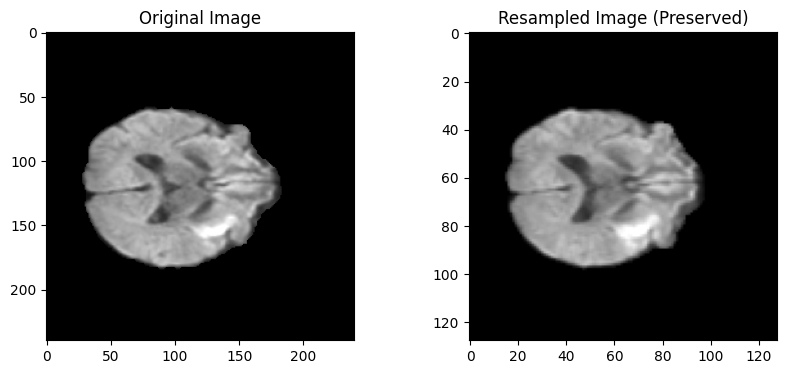

In [16]:
import torchio as tio
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

downsample_shape = (128, 128, 28)
subselection = 'dwi_bet_normalized'

# Load the first NIfTI file in the subselection list
path = all_processed_nifti_filtered[subselection][0]
nifti_img = nib.load(path)
img = nifti_img.get_fdata()
affine = nifti_img.affine  # Get the affine matrix

# Ensure the shape is (D, H, W) and add a channel dim for TorchIO (C, D, H, W)
image_tensor = img[np.newaxis, ...]  # Shape: (1, D, H, W)

# Convert image to a TorchIO Subject with proper metadata
subject = tio.Subject(
    image=tio.ScalarImage(tensor=image_tensor, affine=affine)  # Preserve affine matrix
)

# Use `tio.Resize` instead of `tio.Resample` (Resample expects physical spacing)
resample = tio.Resize(downsample_shape)

# Apply resizing
resampled_subject = resample(subject)
resized_numpy = resampled_subject['image'].numpy().squeeze()  # Remove channel dim

# ✅ Display a single slice (middle slice in axial view)
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img[:, :, img.shape[2] // 2], cmap='gray')
plt.title("Original Image")

plt.subplot(1, 2, 2)
plt.imshow(resized_numpy[:, :, resized_numpy.shape[2] // 2], cmap='gray')
plt.title("Resampled Image (Preserved)")

plt.show()


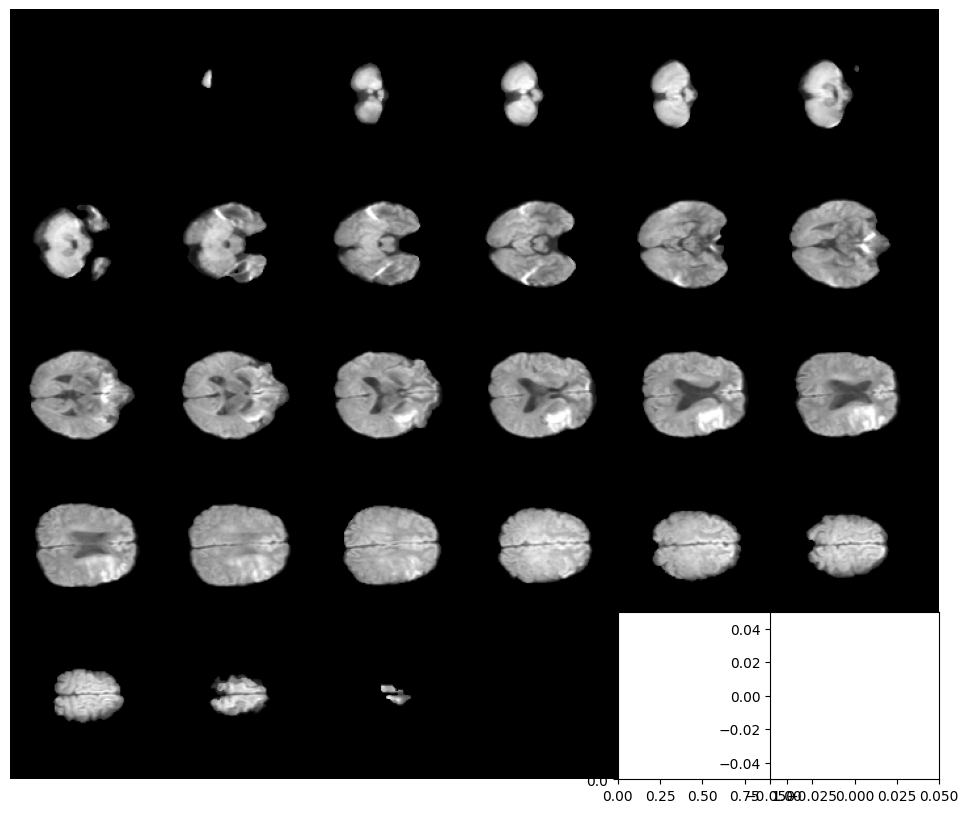

In [17]:
patient_zero_slices = resized_numpy

# Define grid size
rows, cols = 5, 6
fig, axes = plt.subplots(rows, cols, figsize=(12, 10))

# Plot each slice
for i in range(rows * cols):
    if i < patient_zero_slices.shape[-1]:  # Ensure we don't exceed available slices
        ax = axes[i // cols, i % cols]
        ax.imshow(patient_zero_slices[:, :, i], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_frame_on(False)

# Adjust layout to minimize spacing
plt.subplots_adjust(wspace=-0.1, hspace=-0.1)
plt.margins(0, 0)

plt.show()

## Simple itk

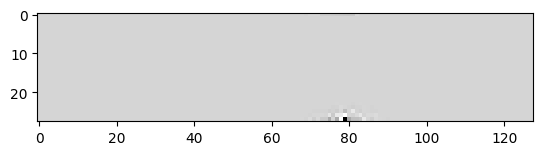

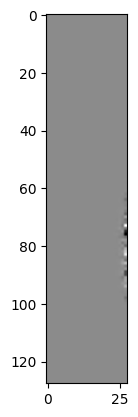

In [12]:
import SimpleITK as sitk

def resample_sitk(image, target_shape):
    image_sitk = sitk.GetImageFromArray(image)
    resampler = sitk.ResampleImageFilter()
    resampler.SetSize(target_shape)
    resampler.SetInterpolator(sitk.sitkBSpline)
    return sitk.GetArrayFromImage(resampler.Execute(image_sitk))

downsample_shape=(128,128,28)

subselection='dwi_bet_normalized'

path=all_processed_nifti_filtered[subselection][0]
img = nib.load(path).get_fdata()
resized_numpy = resample_sitk(img, downsample_shape)
plt.imshow(resized_numpy[:, :, 10], cmap='gray')
plt.show()
resized_numpy = np.transpose(resized_numpy, (2, 0, 1))  # Move the 2nd dimension to the last
plt.imshow(resized_numpy[:, :, 10], cmap='gray')
plt.show()

In [5]:
import SimpleITK as sitk

def resample_sitk(image, target_shape):
    image_sitk = sitk.GetImageFromArray(image)
    resampler = sitk.ResampleImageFilter()
    resampler.SetSize(target_shape)
    resampler.SetInterpolator(sitk.sitkBSpline)
    return sitk.GetArrayFromImage(resampler.Execute(image_sitk))

subselection_list=['dwi_defaced_raw', 'anatomic_defaced_raw','dwi_skull_normalized',
                   'anatomic_skull_normalized','anatomic_defacing_mask',
                   'anatomic_bet_mask', 'dwi_defaced_normalized','anatomic_defaced_normalized',
                   'dwi_skull_raw', 'anatomic_skull_raw','dwi_bet_raw', 'anatomic_bet_raw',
                   'dwi_bet_normalized','anatomic_bet_normalized']

subselection='dwi_bet_normalized'

downsample_shape=(128,128,28)

prestring=f'{len(all_processed_nifti_filtered)}x{downsample_shape[0]}x{downsample_shape[1]}x{downsample_shape[2]}'
SUBSELECTION_PATH=os.path.join(DATA_PATH,'sitk_'+prestring+"_"+subselection+".npz")

if not os.path.exists(SUBSELECTION_PATH):
    print('processing: ',SUBSELECTION_PATH)
    tensorlist=[]
    for path in all_processed_nifti_filtered[subselection]:
        img = nib.load(path)
        tensorlist.append(img.get_fdata())
    image_tensor = np.array(tensorlist)  # Shape: (425, 240, 240, 155)    
    patient_ids = all_processed_nifti_filtered['Patient_ID']  # List of Patient IDs
    resized_patient_images = {}

    for i, pid in enumerate(patient_ids):
        print(f"Processing patient {pid} ({i+1}/{len(patient_ids)})...")
        resized_numpy = resample_sitk(image_tensor[i], downsample_shape)
        resized_patient_images[str(pid)] = resized_numpy


    np.savez_compressed(SUBSELECTION_PATH, **resized_patient_images)

processing:  /home/bule/berner_daten_analyse/data/sitk_413x128x128x28_dwi_bet_normalized.npz
Processing patient 76813 (1/413)...
Processing patient 442968 (2/413)...
Processing patient 481858 (3/413)...
Processing patient 516341 (4/413)...
Processing patient 653853 (5/413)...
Processing patient 744018 (6/413)...
Processing patient 768081 (7/413)...
Processing patient 801402 (8/413)...
Processing patient 830267 (9/413)...
Processing patient 842389 (10/413)...
Processing patient 864099 (11/413)...
Processing patient 876763 (12/413)...
Processing patient 911666 (13/413)...
Processing patient 975885 (14/413)...
Processing patient 991155 (15/413)...
Processing patient 996254 (16/413)...
Processing patient 1029355 (17/413)...
Processing patient 1063871 (18/413)...
Processing patient 1071106 (19/413)...
Processing patient 1097032 (20/413)...
Processing patient 1120794 (21/413)...
Processing patient 1192469 (22/413)...
Processing patient 1241478 (23/413)...
Processing patient 1305751 (24/413).

### check if nans exist

In [ ]:
# subselection_list=['dwi_defaced_raw', 'anatomic_defaced_raw','dwi_skull_normalized',
#                    'anatomic_skull_normalized','anatomic_defacing_mask',
#                    'anatomic_bet_mask', 'dwi_defaced_normalized','anatomic_defaced_normalized',
#                    'dwi_skull_raw', 'anatomic_skull_raw','dwi_bet_raw', 'anatomic_bet_raw',
#                    'dwi_bet_normalized','anatomic_bet_normalized']



# subselection='dwi_bet_normalized'

# downsample_shape=(128,128,28)

# prestring=f'{len(all_processed_nifti_filtered)}x{downsample_shape[0]}x{downsample_shape[1]}x{downsample_shape[2]}'
# SUBSELECTION_PATH=os.path.join(DATA_PATH,prestring+"_"+subselection+".npz")


# print('processing: ',SUBSELECTION_PATH)
# tensorlist=[]
# for path in all_processed_nifti_filtered[subselection]:
#     img = nib.load(path)
#     tensorlist.append(img.get_fdata())
# image_tensor = np.array(tensorlist)  # Shape: (425, 240, 240, 155)
# # np.isnan(tensorlist).sum()

In [ ]:
# data = np.load('/home/bule/berner_daten_analyse/data/413x128x128x28_dwi_bet_normalized.npz')
# X_in =  np.array([data[key].tolist() for key in data.files])
# np.isnan(X_in).sum()

# TABULAR DATA -------------------------------------------------------------------------------------------------

#### Original 

In [33]:
file_path =os.path.join(DATA_PATH, 'clinical','Kopie Olea von Relevent Data Other File 20181005.xlsx')
data = pd.read_excel(file_path)

#remove the last empty rows -> these are just commentings
data = data.iloc[:578] 

print("Unique PIDs before dropping duplicates:", data['PID'].nunique())
data = data.drop_duplicates(subset='PID', keep='first')
print("Unique PIDs after dropping duplicates:", data['PID'].nunique())

data.tail(1)


Unique PIDs before dropping duplicates: 568
Unique PIDs after dropping duplicates: 568


,Nr.,2012-2015 / 2015-2017,Fall Nr,PID,Datum Stroke,Alter (Jahre),Sex 0=Mann 1=Frau,Selbständig vor Stroke: mRS 0-2: 0=nein 1=ja,NIHSS bei Eintritt,NIHSS nach 24 h,...,Ort 2 VA 0=nein 1 =ja,Ort 2 PCA P1 0=nein 1=ja,Ort 2 PCA P2 0=nein 1=ja,SymOnset 1=sicher 2=zuletzt normal 3=wake-up-stroke 4=unklar,Lyse 0=nein 1=ja,"LyseTyp 1=iv 2=ia 3=iv,ia 4=iv und Sono 5=nur mech 6= als bridging geplant (iv) 7=keine",Konventionelle Angiographie 0=nein 1=ja,"Onset to treatment time (Lyse (2015-2017, IA oder Mechanisch 2012-2015)",Zeit Symptombeginn bis Angio [min] / Onset to Groin Puncture,Zeit Symptombeginn bis mechanisch / Stroke to reperfusion time
576,577.0,2015-2017,6.912002e+06,6752837.0,2017-09-03,70.7,0.0,NaN,9.0,1,...,0.0,0.0,0.0,1.0,1,1.0,1.0,95.0,174.0,NaN


In [34]:
image_ids=set(all_processed_nifti_filtered['Patient_ID'])
rows_with_not_nan = data[~data['mRS nach 3 Monaten'].isna()]

print(len(rows_with_not_nan))
intersection_tab_img=set({int(x) for x in image_ids}).intersection(set(rows_with_not_nan['PID']))
len(intersection_tab_img)

477


355

In [35]:
# image
selection_img=all_processed_nifti_filtered[all_processed_nifti_filtered['Patient_ID'].isin(intersection_tab_img)]
# tab
selection_tab=data[data['PID'].isin(intersection_tab_img)]

intersection_df=selection_tab.merge(selection_img, left_on='PID', right_on='Patient_ID', how='inner')
intersection_df['Datum Stroke']=pd.to_datetime(intersection_df['Datum Stroke'])
intersection_df['Date_dwi']=pd.to_datetime(intersection_df['Date_dwi'])

intersection_df['Time_difference']=intersection_df['Date_dwi']-intersection_df['Datum Stroke']
differnce=intersection_df['Time_difference']

filtered_df = intersection_df[intersection_df['Time_difference'] > pd.Timedelta(days=2)]
filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 44 entries, 3 to 352
Data columns (total 72 columns):
 #   Column                                                                                                                                                                  Non-Null Count  Dtype          
---  ------                                                                                                                                                                  --------------  -----          
 0   Nr.                                                                                                                                                                     44 non-null     float64        
 1   2012-2015 / 2015-2017                                                                                                                                                   44 non-null     object         
 2   Fall Nr                                                                     

In [36]:
intersection_df['Time_difference'].apply(lambda x: x.days).value_counts()

Time_difference
 0.0        225
 1.0         70
 2.0          7
 106.0        3
 97.0         2
 99.0         2
 98.0         2
 109.0        2
 3.0          2
 104.0        2
 124.0        1
 145.0        1
 77.0         1
 91.0         1
 122.0        1
 81.0         1
 95.0         1
 131.0        1
 4.0          1
 101.0        1
 120.0        1
 146.0        1
 20.0         1
 90.0         1
 144.0        1
 102.0        1
 167.0        1
 69.0         1
 135.0        1
 134.0        1
-15.0         1
 93.0         1
 24473.0      1
 299.0        1
 129.0        1
 115.0        1
-1.0          1
 149.0        1
 130.0        1
 94.0         1
 62.0         1
Name: count, dtype: int64

In [37]:
final_df = intersection_df[intersection_df['Time_difference'] < pd.Timedelta(days=2)]
print(final_df['PID'].nunique())
final_df.info()

297
<class 'pandas.core.frame.DataFrame'>
Index: 297 entries, 0 to 353
Data columns (total 72 columns):
 #   Column                                                                                                                                                                  Non-Null Count  Dtype          
---  ------                                                                                                                                                                  --------------  -----          
 0   Nr.                                                                                                                                                                     297 non-null    float64        
 1   2012-2015 / 2015-2017                                                                                                                                                   297 non-null    object         
 2   Fall Nr                                                                

In [38]:
final_df.columns

Index(['Nr.', '2012-2015 / 2015-2017', 'Fall Nr', 'PID', 'Datum Stroke',
       'Alter  (Jahre)', 'Sex  0=Mann  1=Frau',
       'Selbständig vor Stroke: mRS 0-2: 0=nein         1=ja',
       'NIHSS bei Eintritt', 'NIHSS nach 24 h', 'NIHSS nach 3 Monaten',
       'mRS nach 3 Monaten', 'Barthel nach 3 Monaten',
       'Rezidiv nach 3 Monaten nein=0; TIA=1; CVI=2; 3=Stummer Infarkt',
       'Datum Rezidiv', 'Clopidogrel pre-stroke 0=nein 1=ja',
       'Ticagrelor pre-stroke 0=nein 1=ja', 'Vit. K ag pre-stroke 0=nein 1=ja',
       'Rivaroxaban/Xarelto pre-stroke 0=nein 1=ja',
       'Dabigatran/Pradaxa pre-stroke 0=nein 1=ja',
       'Parenteral ac pre-stroke 0=nein 1=ja', 'PreStatin 0=nein 1=ja',
       'PreHypert 0=nein 1=ja', 'RR systol bei Eintritt [mmHg]',
       'TOAST 1=Makroangiopathie 2=kardioembolisch 3=Mikroangiopathie 4=Andere 5=ungeklärt (Abklärung komplett) 6=ungeklärt (Abklärung inkomplett) 7=Mehrere mögliche Ursachen',
       'TOAST genaue Ursache in Worten',
       'Notfal

In [39]:
selected_tab=final_df[['Patient_ID','Alter  (Jahre)',
                       'Sex  0=Mann  1=Frau',
                       'NIHSS bei Eintritt',
                       'Selbständig vor Stroke: mRS 0-2: 0=nein         1=ja',
                       'PreHypert 0=nein 1=ja','RR systol bei Eintritt [mmHg]',
                       'TOAST 1=Makroangiopathie 2=kardioembolisch 3=Mikroangiopathie 4=Andere 5=ungeklärt (Abklärung komplett) 6=ungeklärt (Abklärung inkomplett) 7=Mehrere mögliche Ursachen',
                       'mRS nach 3 Monaten','PreStatin 0=nein 1=ja','Parenteral ac pre-stroke 0=nein 1=ja',
                       'Dabigatran/Pradaxa pre-stroke 0=nein 1=ja','Rivaroxaban/Xarelto pre-stroke 0=nein 1=ja',
                       'Vit. K ag pre-stroke 0=nein 1=ja','Ticagrelor pre-stroke 0=nein 1=ja','Clopidogrel pre-stroke 0=nein 1=ja'
                       ]]
selected_tab = selected_tab.rename(columns={
    'Alter  (Jahre)': 'age',
    'Sex  0=Mann  1=Frau':'sex',
    'NIHSS bei Eintritt': 'nihss',
    'Selbständig vor Stroke: mRS 0-2: 0=nein         1=ja': 'selbststaendig',
    'PreHypert 0=nein 1=ja': 'prehypert',
    'RR systol bei Eintritt [mmHg]': 'systol',
    'TOAST 1=Makroangiopathie 2=kardioembolisch 3=Mikroangiopathie 4=Andere 5=ungeklärt (Abklärung komplett) 6=ungeklärt (Abklärung inkomplett) 7=Mehrere mögliche Ursachen': 'toast',
    'PreStatin 0=nein 1=ja': 'MED_prestatin',
    'Parenteral ac pre-stroke 0=nein 1=ja': 'MED_Parenteral',
    'Dabigatran/Pradaxa pre-stroke 0=nein 1=ja': 'MED_Dabigatran_Pradaxa',
    'Rivaroxaban/Xarelto pre-stroke 0=nein 1=ja': 'MED_Rivaroxaban_Xarelto',
    'Vit. K ag pre-stroke 0=nein 1=ja': 'MED_Vit_K_ag',
    'Ticagrelor pre-stroke 0=nein 1=ja': 'MED_Ticagrelor',
    'Clopidogrel pre-stroke 0=nein 1=ja': 'MED_Clopidogrel',
    'mRS nach 3 Monaten': 'mrs'
    
})
# dichotomize outcome
selected_tab['mrs_unfavorable'] = selected_tab['mrs'].apply(lambda x: 0 if x < 3 else 1)
categorical_columns = ['selbststaendig','prehypert','systol','toast','mrs_unfavorable','MED_prestatin','MED_Parenteral',
                       'MED_Dabigatran_Pradaxa','MED_Rivaroxaban_Xarelto','MED_Vit_K_ag','MED_Ticagrelor','MED_Clopidogrel']  # List of categorical columns
selected_tab[categorical_columns] = selected_tab[categorical_columns].astype('category')
selected_tab.sort_values('Patient_ID', inplace=True, ignore_index=True)

selected_tab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Patient_ID               297 non-null    int64   
 1   age                      296 non-null    float64 
 2   sex                      297 non-null    float64 
 3   nihss                    297 non-null    float64 
 4   selbststaendig           266 non-null    category
 5   prehypert                295 non-null    category
 6   systol                   290 non-null    category
 7   toast                    296 non-null    category
 8   mrs                      297 non-null    float64 
 9   MED_prestatin            295 non-null    category
 10  MED_Parenteral           294 non-null    category
 11  MED_Dabigatran_Pradaxa   295 non-null    category
 12  MED_Rivaroxaban_Xarelto  295 non-null    category
 13  MED_Vit_K_ag             295 non-null    category
 14  MED_Ticagr

In [40]:
selected_tab['mrs_unfavorable'].value_counts()

mrs_unfavorable
0    165
1    132
Name: count, dtype: int64

- IMPUTE

In [41]:
selected_tab['Patient_ID'].nunique()

297

In [42]:
columns_to_impute = selected_tab.columns.difference(['mrs','mrs_unfavorable'])

for col in columns_to_impute:
    if selected_tab[col].dtype.name == "category":
        selected_tab[col] = selected_tab[col].cat.codes.replace(-1, np.nan)  # Use np.nan instead of pd.NA

knn_imputer = KNNImputer(n_neighbors=10)
selected_tab[columns_to_impute] = knn_imputer.fit_transform(selected_tab[columns_to_impute])

categorical_columns = ['nihss','sex', 'selbststaendig', 'prehypert', 'systol', 'toast']
for col in categorical_columns:
    if col in selected_tab.columns:
        selected_tab[col] = pd.Categorical(selected_tab[col].round().astype(int))  # Convert back to categorical


# selected_tab.sort_values('Patient_ID', inplace=True)
selected_tab.rename(columns={'Patient_ID':'p_id'}, inplace=True)

selected_tab['p_idx']=selected_tab.index

selected_tab.to_csv(os.path.join(DATA_PATH, 'baseline_bern_test_impute_10n.csv'), index=False)

selected_tab.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   p_id                     297 non-null    float64 
 1   age                      297 non-null    float64 
 2   sex                      297 non-null    category
 3   nihss                    297 non-null    category
 4   selbststaendig           297 non-null    category
 5   prehypert                297 non-null    category
 6   systol                   297 non-null    category
 7   toast                    297 non-null    category
 8   mrs                      297 non-null    float64 
 9   MED_prestatin            297 non-null    float64 
 10  MED_Parenteral           297 non-null    float64 
 11  MED_Dabigatran_Pradaxa   297 non-null    float64 
 12  MED_Rivaroxaban_Xarelto  297 non-null    float64 
 13  MED_Vit_K_ag             297 non-null    float64 
 14  MED_Ticagr

# NORMALZIE AND Save norm file

In [43]:
selected_tab_norm = selected_tab.copy()

transform_cols=['age','nihss','systol','toast']
selected_tab_norm[categorical_columns] = selected_tab_norm[categorical_columns].astype('int64')
# age 
selected_tab_norm['age'] = (selected_tab_norm['age'] - 0) / (110-0)
#nihss
selected_tab_norm['nihss'] = (selected_tab_norm['nihss'] - 0) / (42-0)
#systol
selected_tab_norm['systol'] = (selected_tab_norm['systol'] - 80) / (220-70)

selected_tab_norm['toast'] = selected_tab_norm['toast'].astype(int)

# Apply one-hot encoding
selected_tab_norm = pd.get_dummies(selected_tab_norm, columns=['toast'], drop_first=True)
selected_tab_norm[['toast_1', 'toast_2', 'toast_3', 'toast_4', 'toast_5']] = \
    selected_tab_norm[['toast_1', 'toast_2', 'toast_3', 'toast_4', 'toast_5']].astype(int)
    
selected_tab_norm.to_csv(os.path.join(DATA_PATH, 'baseline_bern_normalized_test.csv'), index=False)  

In [44]:
df = selected_tab
if "mrs" not in df.columns:
    raise ValueError("Column 'mrs' not found in the dataset")

df["unfavorable"] = (df["mrs"] >= 3).astype(int)
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
df[[f'fold{i}' for i in range(10)]] = ""

# Assign folds
for fold, (train_idx, test_idx) in enumerate(skf.split(df, df["mrs"])):
    train_set, test_set = df.iloc[train_idx], df.iloc[test_idx]
    
    skf_val = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    val_size = int(0.1 * len(train_set))
    val_idx = np.random.choice(train_set.index, size=val_size, replace=False)
    val_set = train_set.loc[val_idx]
    
    df.loc[df.index.isin(test_set.index), f'fold{fold}'] = "test"
    df.loc[df.index.isin(val_set.index), f'fold{fold}'] = "val"
    df.loc[(df[f'fold{fold}'] == ""), f'fold{fold}'] = "train"

output_columns = [ "p_id", "mrs", "unfavorable"] + [f'fold{i}' for i in range(10)]

df = df[output_columns]
df['p_idx']=df.index
df.to_csv(os.path.join(DATA_PATH, '10Fold_ids_test.csv'), index=False)
df


/tmp/ipykernel_126677/3092898481.py:25: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['p_idx']=df.index


,p_id,mrs,unfavorable,fold0,fold1,fold2,fold3,fold4,fold5,fold6,fold7,fold8,fold9,p_idx
0,76813.0,0.0,0,train,train,train,train,test,train,train,train,train,train,0
1,442968.0,4.0,1,test,train,train,train,train,train,train,train,train,train,1
2,481858.0,5.0,1,train,val,val,train,train,test,val,train,train,train,2
3,653853.0,6.0,1,train,train,train,test,train,train,train,train,train,train,3
4,768081.0,1.0,0,train,train,train,train,test,train,train,train,train,train,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
292,14150158.0,4.0,1,train,test,train,train,train,train,train,train,train,train,292
293,14239248.0,0.0,0,train,train,train,train,train,train,train,test,train,train,293
294,82298262.0,2.0,0,train,train,train,test,train,train,train,train,train,train,294
295,82364672.0,3.0,1,test,train,train,val,train,val,train,train,train,train,295
